# Assignment 2 — Final Test Evaluation

**Purpose:** Evaluate frozen models once on the previously inspected chronological benchmark.

This notebook is an executable evidence view over the shared local pipeline. The
command-line runner and notebook call the same stage implementation, preventing code
drift. Completed artifacts are reused; no Google Colab or Google Drive runtime is used.


In [1]:
# Local WSL project bootstrap. Dependency installation belongs to the
# locked project environment and is intentionally not repeated in notebooks.
from pathlib import Path
import json
import os
import platform
import sys

candidate = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [candidate, *candidate.parents] if (path / "shared").exists()),
    candidate,
)
if not (PROJECT_ROOT / "shared").exists():
    raise FileNotFoundError(
        "Open this notebook from the local odl-assignment project root."
    )
os.environ["ODL_PROJECT_ROOT"] = str(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from shared.config import PATHS
from shared.runtime import RuntimeOptions
from shared.workflow import run_stage

OPTIONS = RuntimeOptions.from_environment()
print("Project root:", PROJECT_ROOT)
print("Run mode:", OPTIONS.mode)
print("Device policy:", OPTIONS.device)
print("WSL distribution:", os.getenv("WSL_DISTRO_NAME", "not detected"))


I0000 00:00:1786469174.541798    6579 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1786469174.597092    6579 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Project root: /home/nicholas/code/odl-assignment
Run mode: smoke
Device policy: gpu
WSL distribution: Ubuntu-24.04


I0000 00:00:1786469175.722186    6579 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# Run the shared stage or load its verified completed result.
STAGE_SUMMARY = run_stage("evaluate", options=OPTIONS)
STAGE_SUMMARY


{'winner': 'tuned_final',
 'winner_mae': 10.673314219889738,
 'tuned_mae': 10.673314219889738,
 'persistence_mae': 10.844663088849135,
 'improvement_over_persistence_percent': 1.5800294352674165,
 'test_anchors': 10062,
 'statistically_superior_to_basic_lstm': True,
 'run_mode': 'smoke'}

In [3]:
# Record the exact runtime used for this output when preflight evidence exists.
environment_path = PATHS.environment_artifacts / f"environment_{OPTIONS.mode}.json"
ENVIRONMENT = (
    json.loads(environment_path.read_text(encoding="utf-8"))
    if environment_path.exists()
    else {"status": "preflight evidence not yet generated"}
)
ENVIRONMENT


{'captured_at_utc': '2026-08-11T17:24:19.219395+00:00',
 'project_root': '/home/nicholas/code/odl-assignment',
 'platform': 'Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39',
 'system': 'Linux',
 'release': '6.6.87.2-microsoft-standard-WSL2',
 'python': '3.12.3',
 'wsl_distribution': 'Ubuntu-24.04',
 'device': 'gpu',
 'tensorflow_gpu_devices': ['/physical_device:GPU:0'],
 'batch_size': 256,
 'mixed_precision': False,
 'nvidia_smi': {'available': True,
  'name': 'NVIDIA GeForce RTX 3050 Laptop GPU',
  'driver_version': '591.74',
  'memory.total': '4096',
  'memory.used': '167',
  'utilization.gpu': '3',
  'temperature.gpu': '56',
  'power.draw': '17.34'},
 'packages': {'tensorflow': '2.21.0',
  'keras-tuner': '1.4.8',
  'numpy': '2.3.5',
  'pandas': '2.3.3',
  'pyarrow': '25.0.0',
  'scikit-learn': '1.9.0',
  'matplotlib': '3.11.1',
  'seaborn': '0.13.2'},
 'git': {'available': True,
  'revision': '7b64970eb262a89eacb2684e5f337af7b67c5d4b',
  'dirty': True},
 'experiment_co

## Overall comparison and computational evidence

**Decision.** MAE is primary because it is interpretable in µg/m³ and less dominated by
spikes; RMSE exposes large misses, R² measures explained variation, and sMAPE provides
relative error. Parameter and timing evidence adds efficiency. **Trade-off.** No single
metric captures public-health costs, so all claims use the metric panel and subgroup
evidence. This period is called a frozen benchmark—not untouched—because aggregate
results from the earlier methodology were already inspected.


In [4]:
import pandas as pd
from IPython.display import Image, display

suffix = OPTIONS.artifact_suffix
overall_metrics = pd.read_csv(
    PATHS.assignment2_tables / f"final_overall_metrics{suffix}.csv"
)
inference = pd.read_csv(
    PATHS.assignment2_tables / f"inference_timing{suffix}.csv"
)
display(overall_metrics)
display(inference)


,model,n,mae,rmse,r2,smape_percent
0,tuned_final,10062,10.673314,20.415185,0.946754,21.847922
1,persistence,10062,10.844663,20.653041,0.945506,22.139761
2,basic_cnn,10062,13.777579,23.542508,0.929192,28.467087
3,basic_lstm,10062,24.860981,53.160890,0.638953,32.040479
4,seasonal_persistence,10062,62.354105,94.628100,-0.143984,83.502328


,model,inference_seconds,parameters
0,basic_lstm,0.330895,29249
1,basic_cnn,0.335578,22913
2,tuned_final,0.367125,95361


## Robustness by station, season, and pollution intensity

Grouped metrics expose where aggregate performance hides difficult conditions. Seed
tables compare every model rather than only the winner.


In [5]:
station_metrics = pd.read_csv(
    PATHS.assignment2_tables / f"final_metrics_by_station{suffix}.csv"
)
season_metrics = pd.read_csv(
    PATHS.assignment2_tables / f"final_metrics_by_season{suffix}.csv"
)
pollution_metrics = pd.read_csv(
    PATHS.assignment2_tables / f"final_metrics_by_pollution_band{suffix}.csv"
)
residual_diagnostics = pd.read_csv(
    PATHS.assignment2_tables / f"residual_diagnostics{suffix}.csv"
)
display(station_metrics)
display(season_metrics)
display(pollution_metrics)
display(residual_diagnostics)


,model,station,n,mae,rmse,r2,smape_percent
0,persistence,Aotizhongxin,5029,11.054683,21.011762,0.950379,21.138972
1,persistence,Changping,5033,10.634810,20.288271,0.938301,23.139755
2,seasonal_persistence,Aotizhongxin,5029,67.296282,101.296969,-0.153279,84.832648
3,seasonal_persistence,Changping,5033,57.415855,87.458088,-0.146529,82.173065
4,basic_lstm,Aotizhongxin,5029,27.951291,58.603473,0.613999,32.986361
5,basic_lstm,Changping,5033,21.773128,47.098587,0.667493,31.095349
6,basic_cnn,Aotizhongxin,5029,14.329885,24.520657,0.932422,27.744201
7,basic_cnn,Changping,5033,13.225713,22.522746,0.923963,29.189398
8,tuned_final,Aotizhongxin,5029,10.813030,20.702341,0.951830,20.761327
9,tuned_final,Changping,5033,10.533710,20.124165,0.939296,22.933654


,model,season,n,mae,rmse,r2,smape_percent
0,persistence,autumn,4304,9.563662,16.468442,0.942720,20.966726
1,persistence,summer,1473,6.430414,10.038284,0.897483,23.248531
2,persistence,winter,4285,13.648775,26.354601,0.943934,22.936849
3,seasonal_persistence,autumn,4304,52.598978,72.050223,-0.096402,78.038512
4,seasonal_persistence,summer,1473,26.834352,36.864046,-0.382550,66.342955
5,seasonal_persistence,winter,4285,84.362660,123.876639,-0.238699,94.889029
6,basic_lstm,autumn,4304,18.061357,31.558702,0.789653,28.032544
7,basic_lstm,summer,1473,9.614951,13.453646,0.815857,29.937963
8,basic_lstm,winter,4285,36.931690,74.656474,0.550094,36.788941
9,basic_cnn,autumn,4304,12.782605,18.857623,0.924894,29.334167


,model,pollution_band,n,mae,rmse,r2,smape_percent
0,persistence,low,3064,4.922650,12.378113,-5.919997,36.833512
1,persistence,moderate,4253,9.821303,17.369635,0.503536,19.111477
2,persistence,high,1448,15.785912,25.171017,-0.515415,11.642202
3,persistence,extreme,1297,22.673863,35.362382,0.833251,9.077390
4,seasonal_persistence,low,3064,57.934399,104.602722,-493.177471,102.604821
5,seasonal_persistence,moderate,4253,46.821303,67.134870,-6.416565,82.543426
6,seasonal_persistence,high,1448,68.600829,82.332863,-15.213486,66.910228
7,seasonal_persistence,extreme,1297,116.754819,145.850540,-1.836585,60.043215
8,basic_lstm,low,3064,6.050519,12.248164,-5.775462,41.402090
9,basic_lstm,moderate,4253,13.890178,19.765108,0.357157,25.944643


,model,mean_residual,median_residual,underprediction_percent,extreme_mean_residual,extreme_underprediction_percent
0,persistence,-0.007255,1.000000,50.457166,5.020817,56.129530
1,seasonal_persistence,-0.220334,7.000000,56.946929,89.473400,82.960678
2,basic_lstm,14.572381,1.668887,55.466110,112.380784,100.000000
3,basic_cnn,4.300909,3.594733,64.937388,10.627666,61.989206
4,tuned_final,-0.168950,0.233067,51.252236,6.622872,60.292984


## Temporal uncertainty and diagnostic plots

Paired station-day block bootstrap intervals preserve more temporal dependence than
resampling independent hours. Diagnostic plots reveal bias, extremes, and time-local
behaviour.


,comparison,mean_mae_difference_a_minus_b,ci95_lower,ci95_upper,n_station_day_blocks,bootstrap_samples
0,tuned_final_vs_basic_lstm,-14.076311,-17.365467,-10.935003,424,100
1,tuned_final_vs_basic_cnn,-3.105315,-3.469244,-2.748543,424,100
2,tuned_final_vs_persistence,-0.171157,-0.211816,-0.136044,424,100


{'statistically_superior_to_basic_lstm': True,
 'rule': 'claim superiority only when the paired block-bootstrap CI is below zero',
 'test_description': 'frozen chronological benchmark previously inspected',
 'test_used_for_model_selection': False}

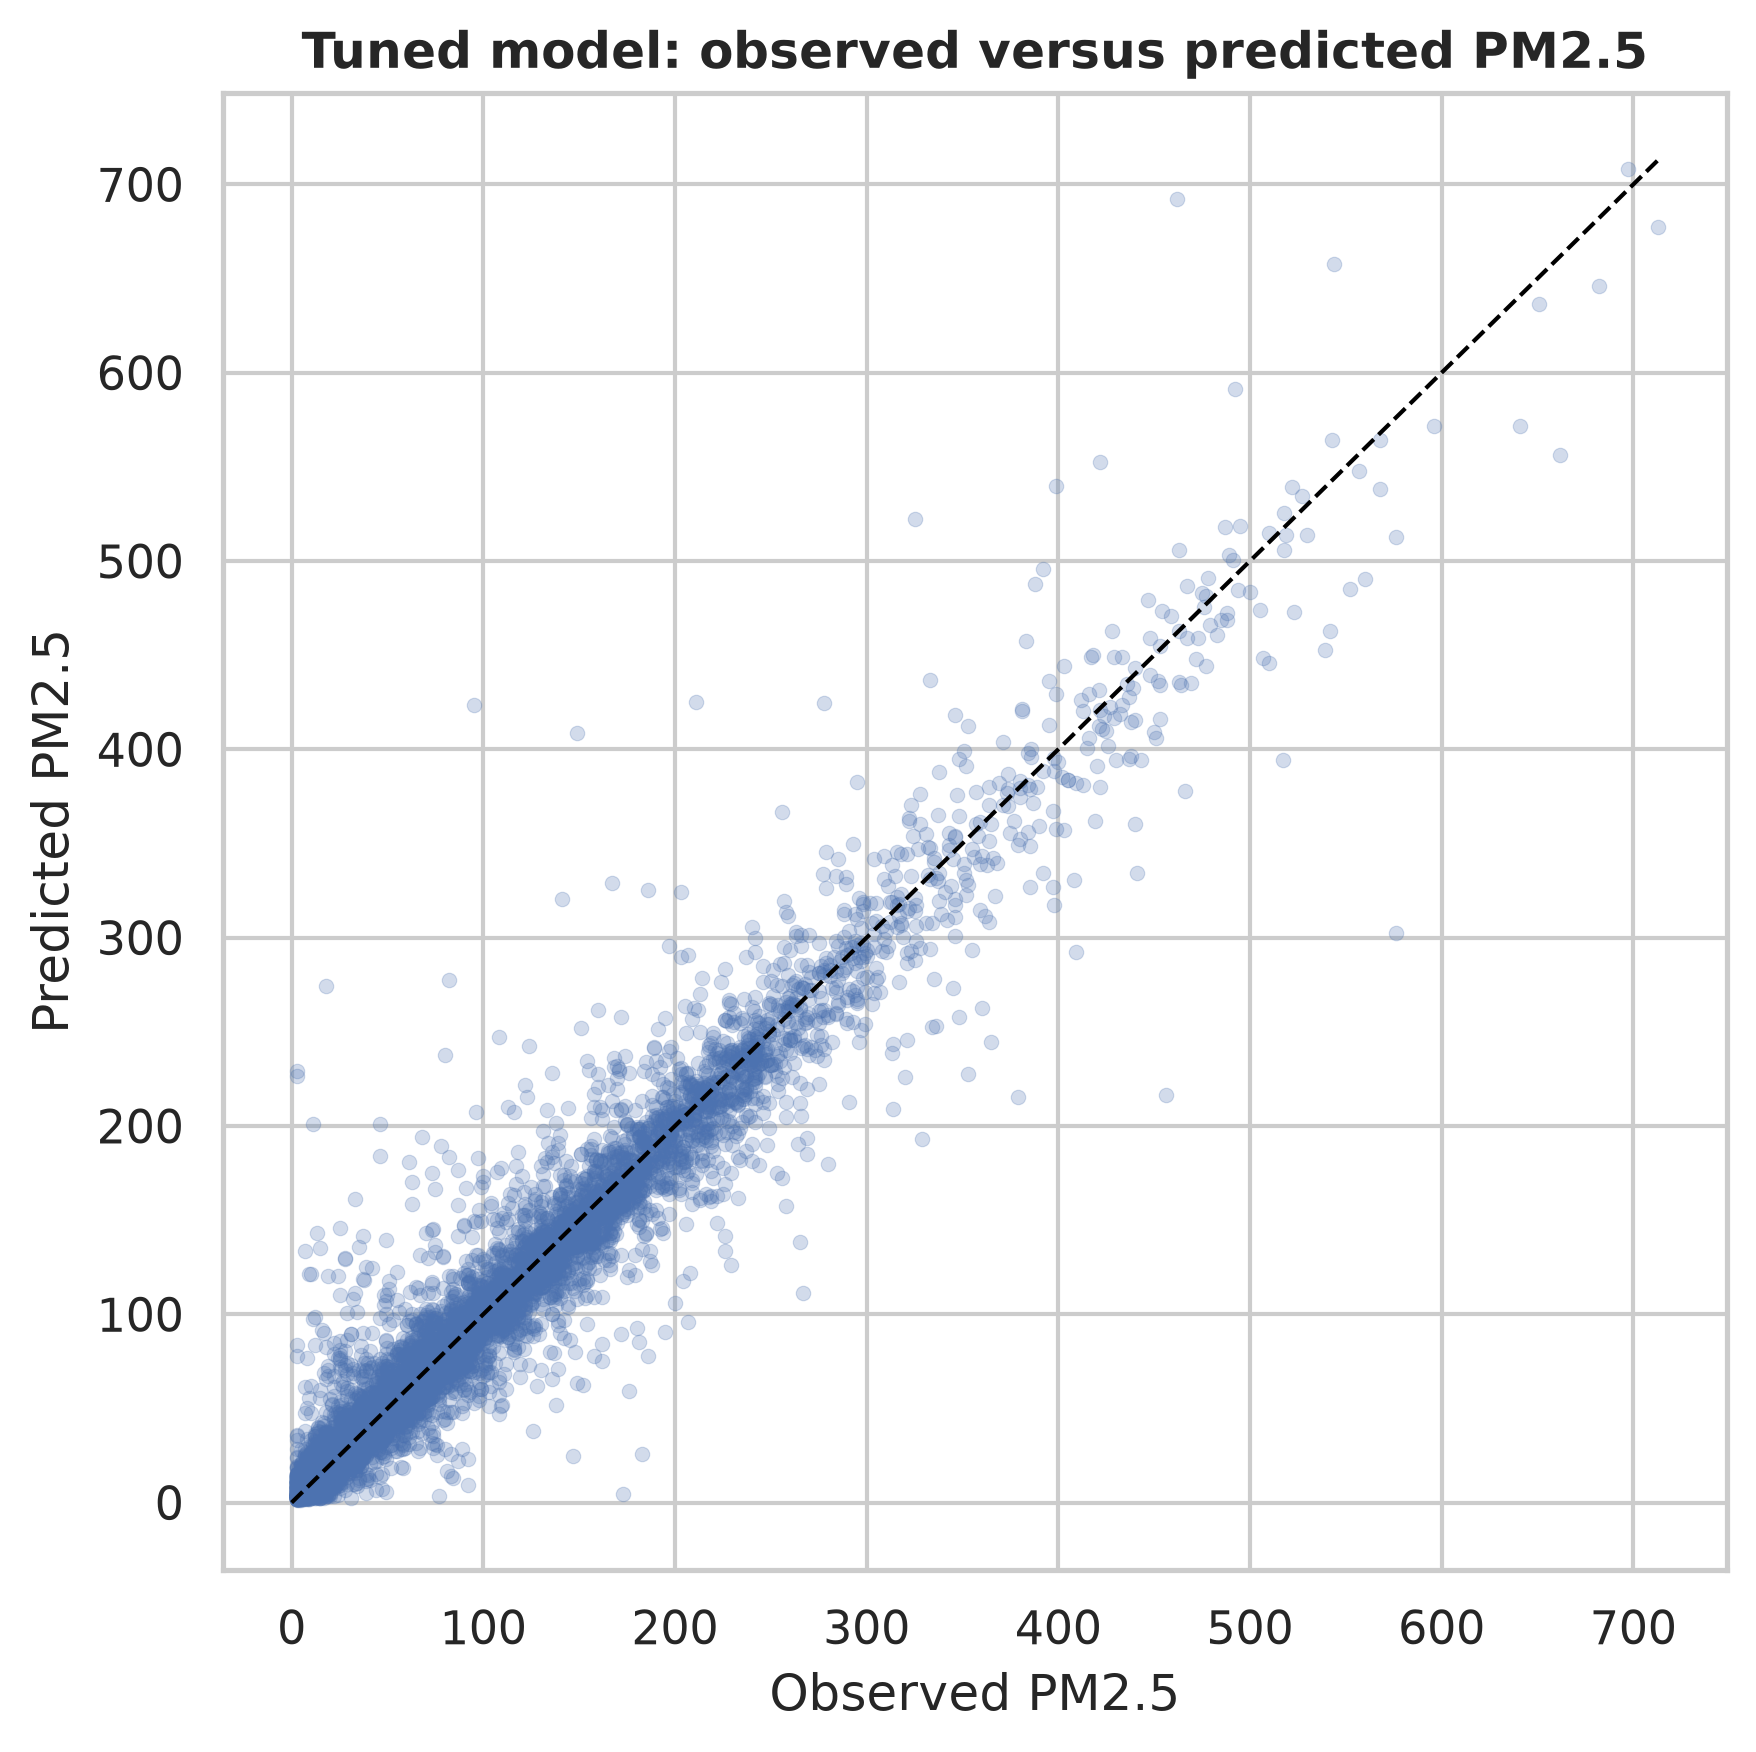

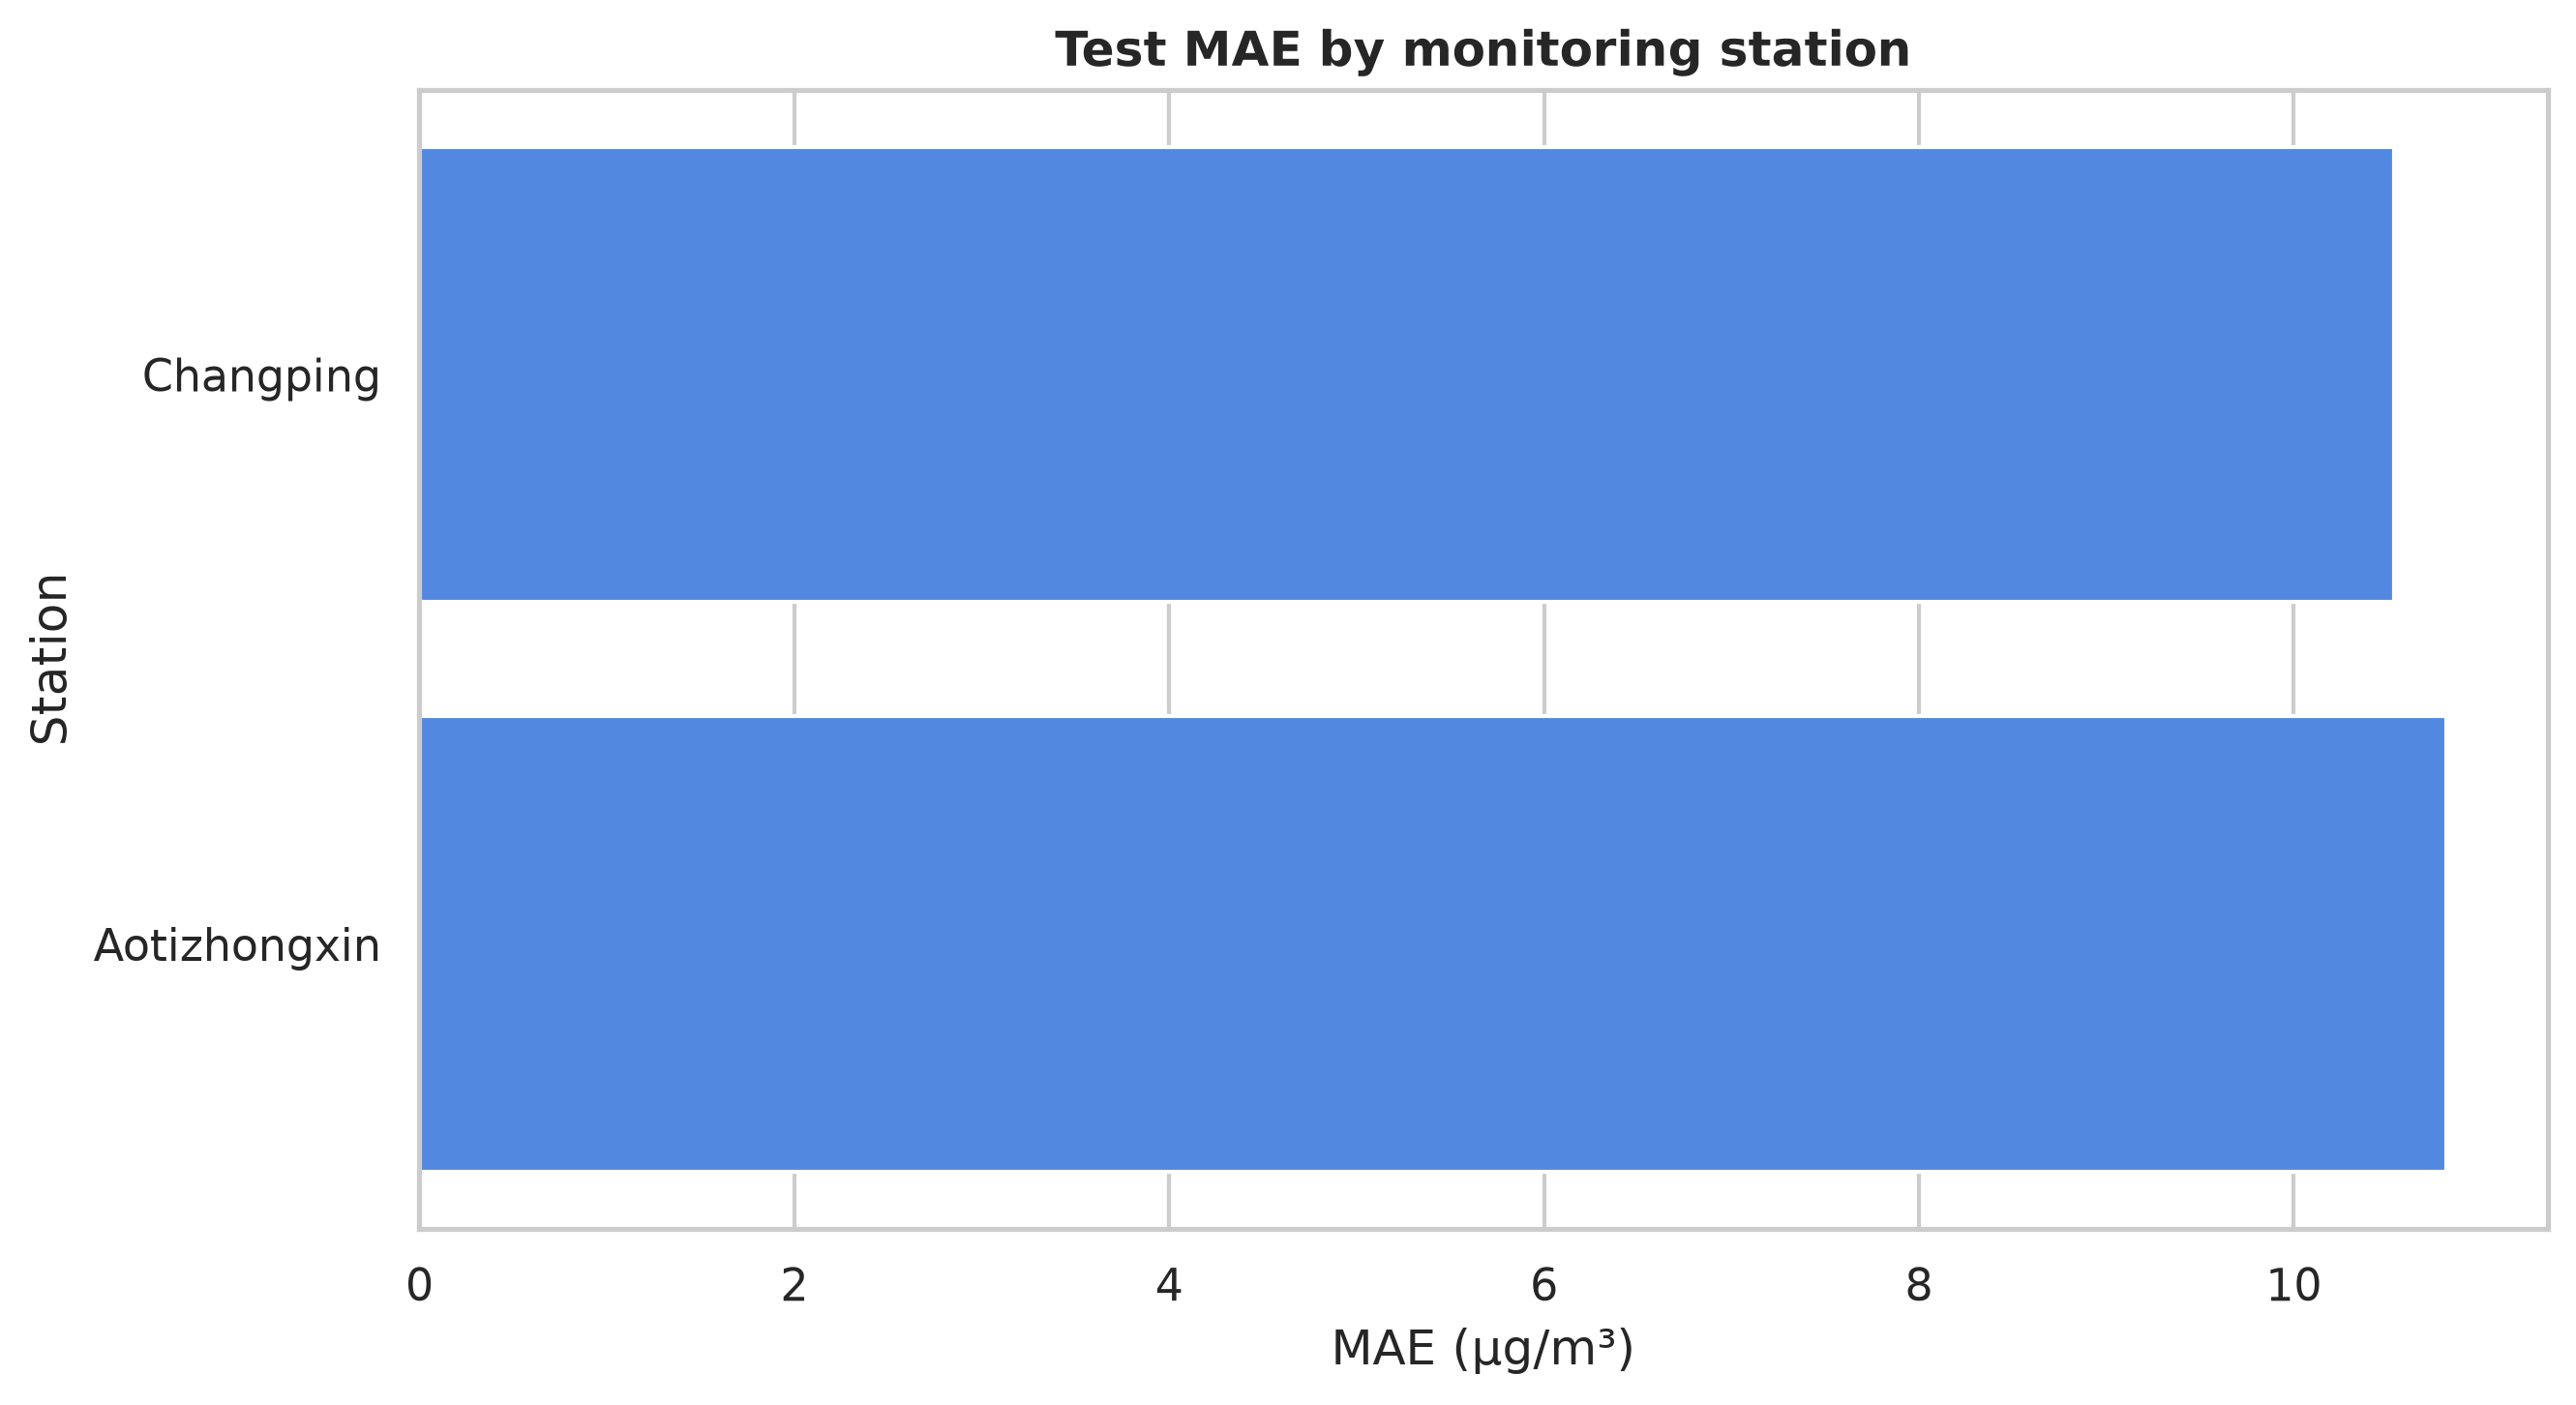

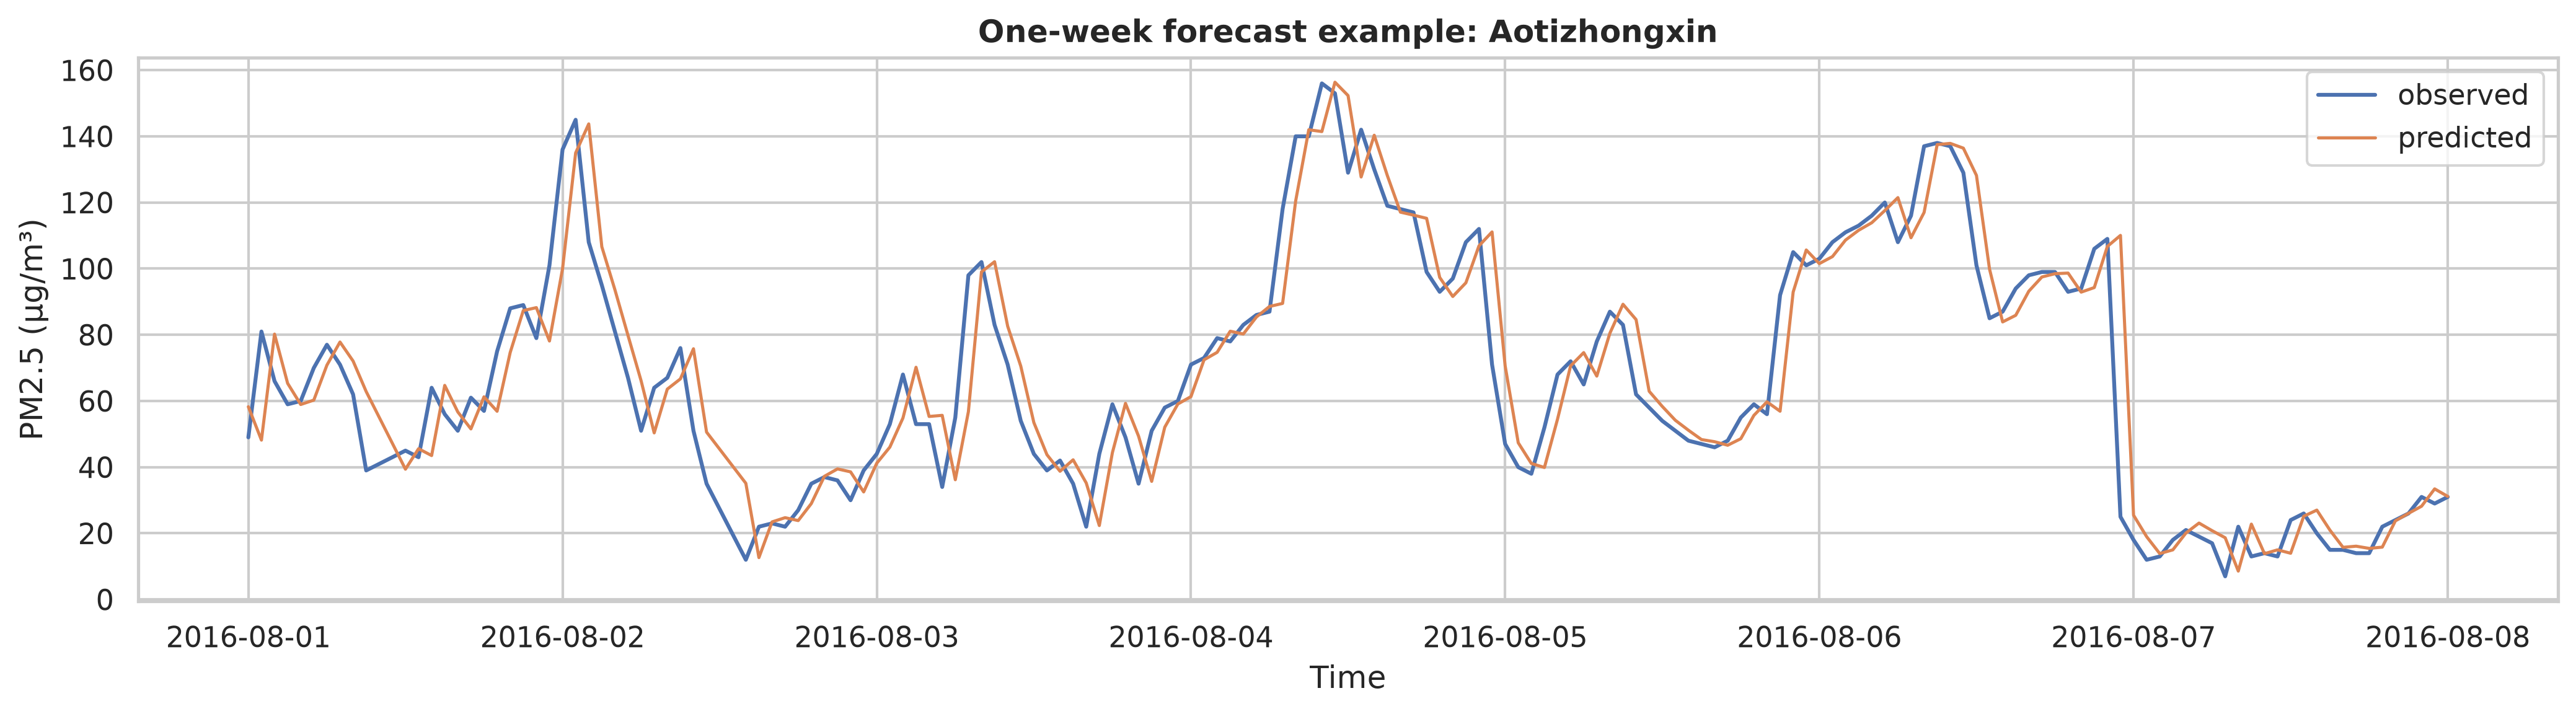

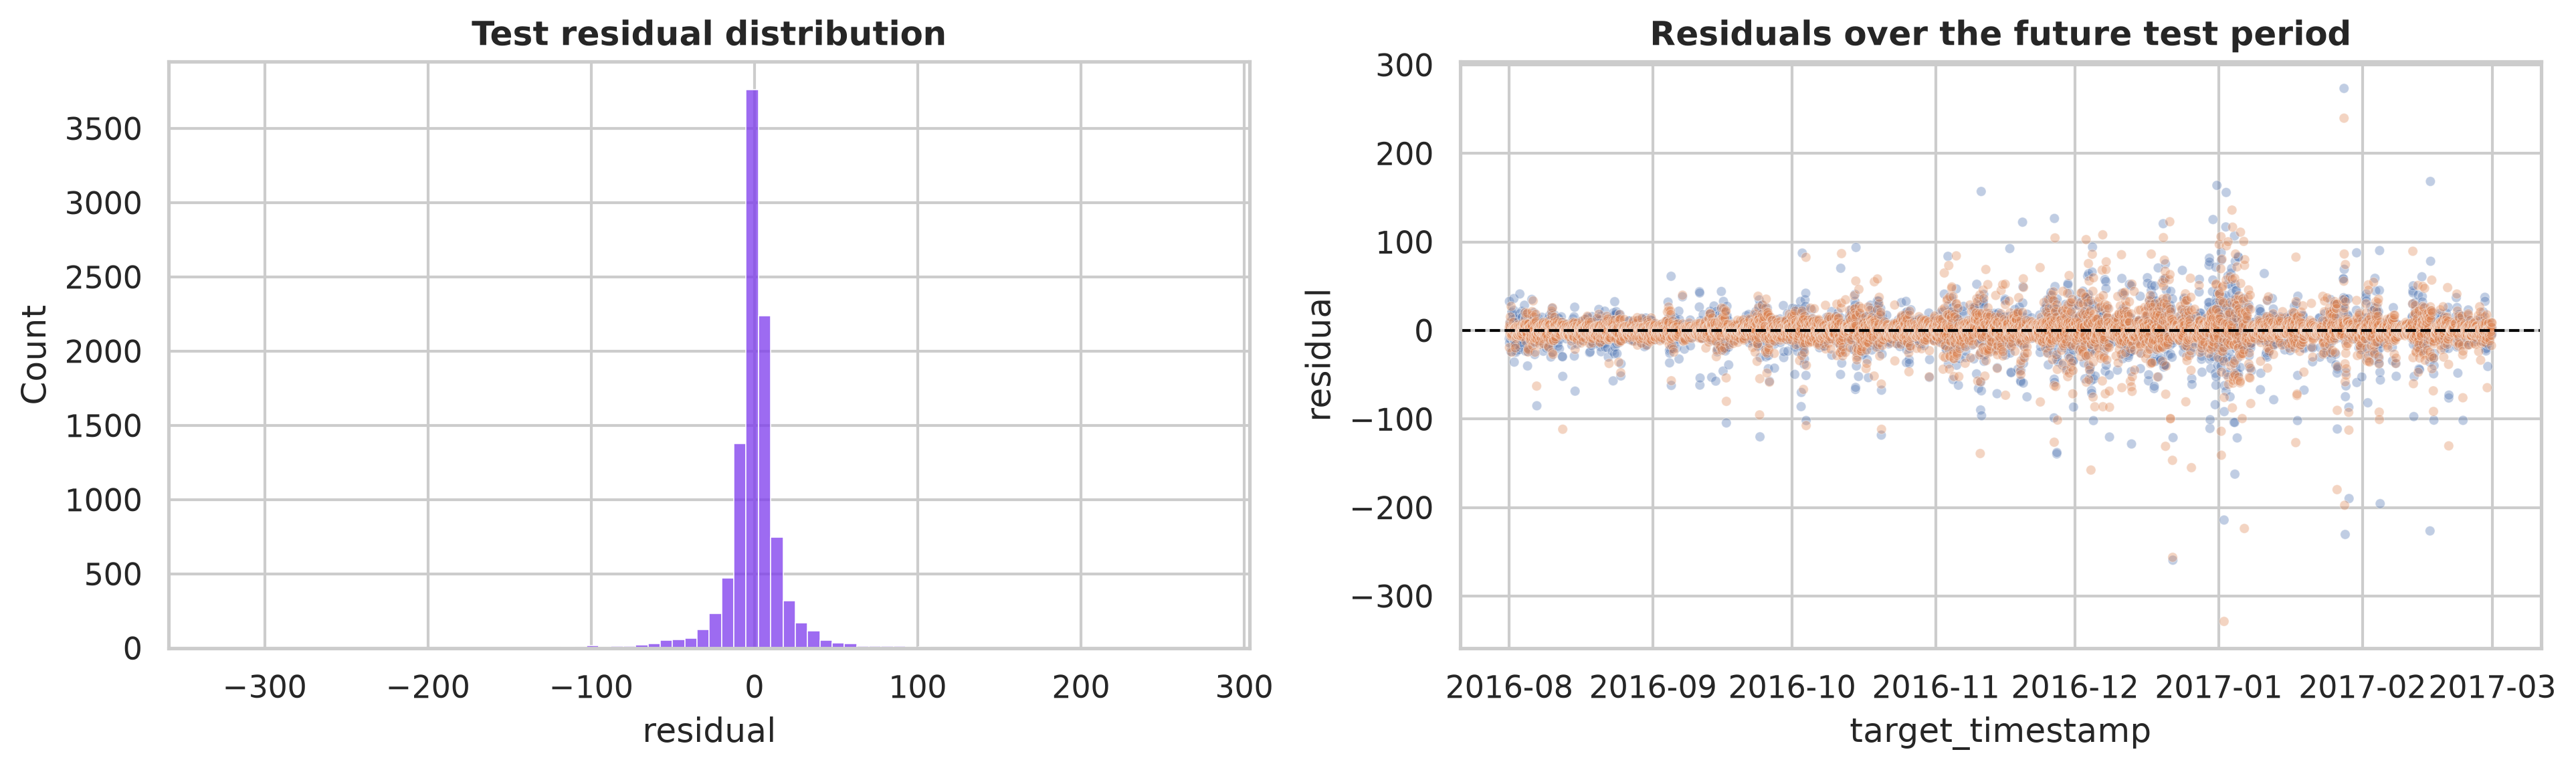

Published metrics are not directly comparable when datasets, horizons, splits, or preprocessing differ. Final benchmark evaluation complete.


In [6]:
bootstrap = pd.read_csv(
    PATHS.assignment2_tables / f"paired_block_bootstrap{suffix}.csv"
)
display(bootstrap)
optimization_claim = json.loads(
    (PATHS.assignment2_tables / f"optimization_claim{suffix}.json").read_text(
        encoding="utf-8"
    )
)
display(optimization_claim)
display(Image(filename=str(
    PATHS.assignment2_figures / f"final_actual_vs_predicted{suffix}.png"
)))
display(Image(filename=str(
    PATHS.assignment2_figures / f"final_station_mae{suffix}.png"
)))
display(Image(filename=str(
    PATHS.assignment2_figures / f"final_example_week{suffix}.png"
)))
display(Image(filename=str(
    PATHS.assignment2_figures / f"final_residual_analysis{suffix}.png"
)))
print(
    "Published metrics are not directly comparable when datasets, horizons, splits, "
    "or preprocessing differ. Final benchmark evaluation complete."
)
